# Age structure changes country and organ comparisons

Compare 2023, both sexes, crude rates with age-standardized rates (ASDRs), per 100,000. Country deaths use sums of WHO fine-age cause ASDRs; DALYs use the seven-bin approximation. Higher burden ranks first. Positive rank change means movement toward rank one; ties receive average ranks.

In [1]:
from pathlib import Path
import json
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "contracts/organs.json").exists())
sys.path.insert(0, str(root / "pipeline/src"))
import pandas as pd
from IPython.display import display, Markdown
from visceral_pipeline.analysis.data import CACHE, load_inputs, load_results
from visceral_pipeline.analysis import comparisons, sensitivity, clustering, plots
inputs, frames = load_inputs(), load_results()
meta = json.loads((CACHE / "metadata.json").read_text())
pd.set_option("display.max_rows", 65)
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 140)


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\louis\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


,measure,organ,n,rho,max_abs_rank_change
0,dalys,bladder,185,0.854564,88.0
1,dalys,blood_immune,185,0.949397,54.0
2,dalys,bones_joints,185,0.827302,100.0
3,dalys,brain,185,0.478634,134.0
4,dalys,breast,185,0.599665,99.0
5,dalys,colon_rectum,185,0.940072,58.0
6,dalys,congenital,185,0.846353,86.0
7,dalys,diabetes_endocrine,185,0.512824,109.0
8,dalys,ears,185,0.002663,149.0
9,dalys,esophagus,185,0.835448,75.0


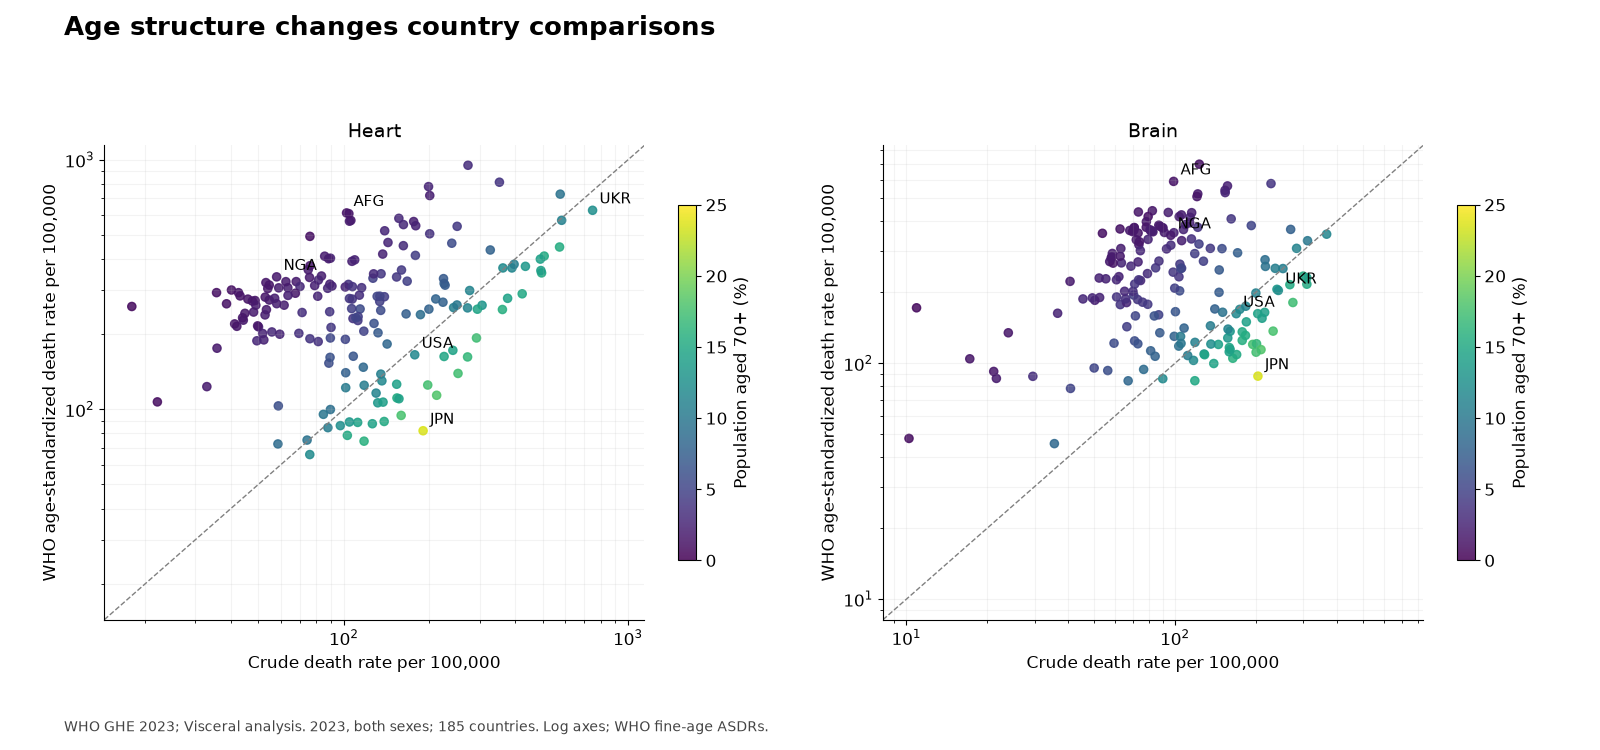

In [2]:
current = inputs['burden'].query("year==2023 and sex=='both' and location!='WLD'")
ranks = comparisons.rank_comparison(current,'rate','ageStdRate',['measure','organ'])
display(comparisons.rank_correlations(ranks,['measure','organ']))
plots.display_figure(plots.rankings(frames,meta))

## Concrete worked examples and largest movers

Japan and Nigeria illustrate how different age structures change comparisons. The observed population share aged 70+ supplies context; it is not an estimated causal aging effect. The table reports both heart and brain. Below it, movers are selected separately for each measure and organ, so small-burden groups do not obscure the large groups.

In [3]:
example = frames['country_ranks'].query("organ in ['heart','brain'] and location in ['JPN','NGA']")
display(example[['measure','location','organ','rate','ageStdRate','rank_a','rank_b','population_70_plus']].sort_values(['measure','organ','location']))
movers = frames['country_ranks'].assign(abs_change=lambda x:x.rank_change.abs()).sort_values('abs_change',ascending=False)
display(movers.groupby(['measure','organ'],sort=False).head(1)[['measure','organ','location','rank_a','rank_b','rank_change']].sort_values(['measure','organ']))

,measure,location,organ,rate,ageStdRate,rank_a,rank_b,population_70_plus
18,dalys,JPN,brain,4300.385077,2619.290561,42.0,176.0,23.625642
9544,dalys,NGA,brain,5666.146815,8077.427579,15.0,19.0,1.715601
198,dalys,JPN,heart,2679.265980,1517.876461,83.0,176.0,23.625642
9799,dalys,NGA,heart,1588.339104,5363.046876,151.0,62.0,1.715601
7822,deaths,JPN,brain,203.457589,88.150627,21.0,177.0,23.625642
3248,deaths,NGA,brain,96.365084,348.522721,96.0,45.0,1.715601
8002,deaths,JPN,heart,189.895362,81.994552,43.0,180.0,23.625642
3503,deaths,NGA,heart,57.946541,339.275639,152.0,46.0,1.715601


,measure,organ,location,rank_a,rank_b,rank_change
9095,dalys,bladder,QAT,115.0,27.0,88.0
5684,dalys,blood_immune,QAT,176.0,122.0,54.0
9424,dalys,bones_joints,CHN,76.0,176.0,-100.0
18,dalys,brain,JPN,42.0,176.0,-134.0
6133,dalys,breast,CAF,108.0,9.0,99.0
8991,dalys,colon_rectum,PSE,89.0,31.0,58.0
1658,dalys,congenital,TTO,95.0,9.0,86.0
6410,dalys,diabetes_endocrine,UGA,180.0,71.0,109.0
90,dalys,ears,JPN,1.0,150.0,-149.0
9864,dalys,esophagus,SOM,93.0,18.0,75.0


## The ranking of groups within a country also changes

The first table summarizes country-level profile agreement across the 30 nonempty groups; the second shows world and worked-example group ranks. Crude and standardized rankings answer different descriptive questions. Age adjustment does not make a ranking a health-system score. Rare groups with negligible deaths can have unstable rankings; muscles are structurally empty and have undefined rank correlation.

In [4]:
display(frames['profile_correlations'].groupby('measure').rho.describe())
display(frames['profile_ranks'].query("location in ['WLD','JPN','NGA'] and organ in ['heart','brain','lungs','injuries','maternal_neonatal']")[['measure','location','organ','rate','ageStdRate','rank_a','rank_b']].sort_values(['measure','location','rank_b']))

,count,mean,std,min,25%,50%,75%,max
measure,,,,,,,,
dalys,186.0,0.979588,0.014017,0.933704,0.969855,0.981758,0.991546,1.0
deaths,186.0,0.974630,0.022310,0.848242,0.959059,0.977753,0.995105,1.0


,measure,location,organ,rate,ageStdRate,rank_a,rank_b
18,dalys,JPN,brain,4300.385077,2619.290561,1.0,2.0
162,dalys,JPN,lungs,4166.227150,2403.509057,2.0,3.0
6347,dalys,JPN,injuries,2830.389657,2266.594452,5.0,4.0
198,dalys,JPN,heart,2679.265980,1517.876461,6.0,7.0
6275,dalys,JPN,maternal_neonatal,157.641051,210.364020,23.0,20.0
9444,dalys,NGA,lungs,9888.474822,9019.309328,3.0,1.0
9240,dalys,NGA,brain,5666.146815,8077.427579,4.0,2.0
1485,dalys,NGA,maternal_neonatal,10093.243837,5647.977743,2.0,4.0
9495,dalys,NGA,heart,1588.339104,5363.046876,10.0,5.0
1587,dalys,NGA,injuries,3528.857098,3779.562107,6.0,6.0
